Students Names: Brahim Ahmed  &  Othman El-Kurdi

Students IDs:  202510201 &  202511290

In [ ]:
# ============================
# 📦 Step 1: Install & Import Dependencies
# ============================

# Install OpenCV if not already installed
!pip install opencv-python --quiet

# Import essential libraries
import cv2          # For image processing
import numpy as np  # For numerical computations
import glob         # For reading image files from folder
import os           # For file and path management

print("✅ Libraries imported successfully.")

✅ Libraries imported successfully.


In [ ]:
# ============================
# 📸 Step 2: Obtain Images
# ============================
# Option 1: Upload images manually to Colab
from google.colab import files

print("⬆️ Please upload your 55 images (JPG/PNG).")
uploaded = files.upload()  # You can select multiple files at once

# Option 2: If you already have them in a folder, e.g. '/content/images/'
# You can skip the upload and directly read them from there.

⬆️ Please upload your 55 images (JPG/PNG).


Saving dog (55).jpg to dog (55).jpg
Saving dog (54).jpg to dog (54).jpg
Saving dog (53).jpg to dog (53).jpg
Saving dog (52).jpg to dog (52).jpg
Saving dog (51).jpg to dog (51).jpg
Saving dog (50).jpg to dog (50).jpg
Saving dog (49).jpg to dog (49).jpg
Saving dog (48).jpg to dog (48).jpg
Saving dog (47).jpg to dog (47).jpg
Saving dog (46).jpg to dog (46).jpg
Saving dog (45).jpg to dog (45).jpg
Saving dog (44).jpg to dog (44).jpg
Saving dog (43).jpg to dog (43).jpg
Saving dog (42).jpg to dog (42).jpg
Saving dog (41).jpg to dog (41).jpg
Saving dog (40).jpg to dog (40).jpg
Saving dog (39).jpg to dog (39).jpg
Saving dog (38).jpg to dog (38).jpg
Saving dog (37).jpg to dog (37).jpg
Saving dog (36).jpg to dog (36).jpg
Saving dog (35).jpg to dog (35).jpg
Saving dog (34).jpg to dog (34).jpg
Saving dog (33).jpg to dog (33).jpg
Saving dog (32).jpg to dog (32).jpg
Saving dog (31).jpg to dog (31).jpg
Saving dog (30).jpg to dog (30).jpg
Saving dog (29).jpg to dog (29).jpg
Saving dog (28).jpg to dog (

In [ ]:
# ============================
# ⚫ Step 3: Read Images in Grayscale
# ============================

# Create a list to store grayscale images
gray_images = []

# Loop through all uploaded images
for filename in uploaded.keys():
    # Read image as grayscale
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"⚠️ Could not read {filename}. Skipping...")
        continue

    # Resize all images to 64x64 pixels to ensure consistent dimensions
    img_resized = cv2.resize(img, (64, 64))

    # Append to list
    gray_images.append(img_resized)

print(f"✅ Loaded {len(gray_images)} grayscale images successfully.")

✅ Loaded 55 grayscale images successfully.


In [ ]:
# ============================
# 🧮 Step 4: Construct Image Matrix (55 x 4096)
# ============================

# Check if we have the expected number of images
num_images = len(gray_images)
img_size = 64 * 64  # 4096 pixels per image

# Flatten each image (convert from 2D 64x64 to 1D 4096)
flattened_images = [img.flatten() for img in gray_images]

# Create a matrix of shape (num_images, 4096)
image_matrix = np.array(flattened_images)

print(f"✅ Matrix constructed with shape: {image_matrix.shape}")
print("Expected shape: (55, 4096)")

✅ Matrix constructed with shape: (55, 4096)
Expected shape: (55, 4096)


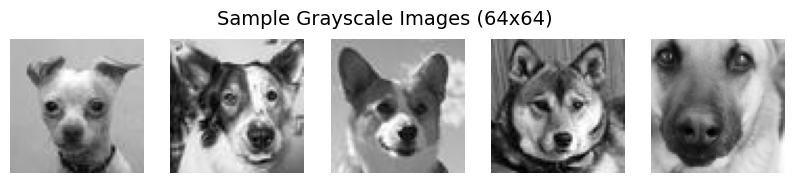

In [ ]:
# ============================
# 🖼️ Step 5: Visualize Sample Images
# ============================
import matplotlib.pyplot as plt

# Display first 5 images to verify
plt.figure(figsize=(10, 2))
for i in range(min(5, len(gray_images))):
    plt.subplot(1, 5, i+1)
    plt.imshow(gray_images[i], cmap='gray')
    plt.axis('off')
plt.suptitle("Sample Grayscale Images (64x64)", fontsize=14)
plt.show()

In [ ]:
# ============================
# 🧮 Step 6: Center the Data (Mean Normalization)
# ============================

# Calculate the mean of each feature (pixel)
mean_vector = np.mean(image_matrix, axis=0)

# Center the data by subtracting the mean from each image vector
centered_matrix = image_matrix - mean_vector

print("✅ Data centered successfully.")
print(f"Mean vector shape: {mean_vector.shape}")
print(f"Centered matrix shape: {centered_matrix.shape}")

✅ Data centered successfully.
Mean vector shape: (4096,)
Centered matrix shape: (55, 4096)


In [ ]:
# ============================
# 📊 Step 7: Compute Covariance Matrix
# ============================

# Covariance matrix formula: (1 / (N-1)) * X^T * X
# Note: X here is the centered data (each row = image)
covariance_matrix = np.cov(centered_matrix, rowvar=False)

print("✅ Covariance matrix calculated successfully.")
print(f"Covariance matrix shape: {covariance_matrix.shape}")

✅ Covariance matrix calculated successfully.
Covariance matrix shape: (4096, 4096)


In [ ]:
# ============================
# 🔢 Step 8: Compute Eigenvalues and Eigenvectors
# ============================

# Using numpy to find eigenvalues and eigenvectors of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

# Sort eigenvalues and eigenvectors in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("✅ Eigen decomposition completed.")
print(f"Number of Eigenvectors: {eigenvectors.shape[1]}")

✅ Eigen decomposition completed.
Number of Eigenvectors: 4096


Top 5 Eigenvalues (representing variance captured):

Eigenvalue 1: 3529064.1906876974
Eigenvalue 2: 1886026.7049186283
Eigenvalue 3: 1401025.0347421016
Eigenvalue 4: 1213855.4026092621
Eigenvalue 5: 919675.8422270186

INTERPRETATION:

• Each eigenvalue represents how much variance (information) is captured by its corresponding eigenvector.
• Larger eigenvalues = more important features captured from the dataset.
• These top eigenvectors define the main patterns that vary between images (e.g., shape, texture, brightness).
• The eigenvectors associated with the largest eigenvalues are called "principal components."
• When reshaped into 64×64 images, these eigenvectors are known as "Eigenfaces."
• They do NOT represent real images, but show the most dominant directions of variation among all 55 dog images.



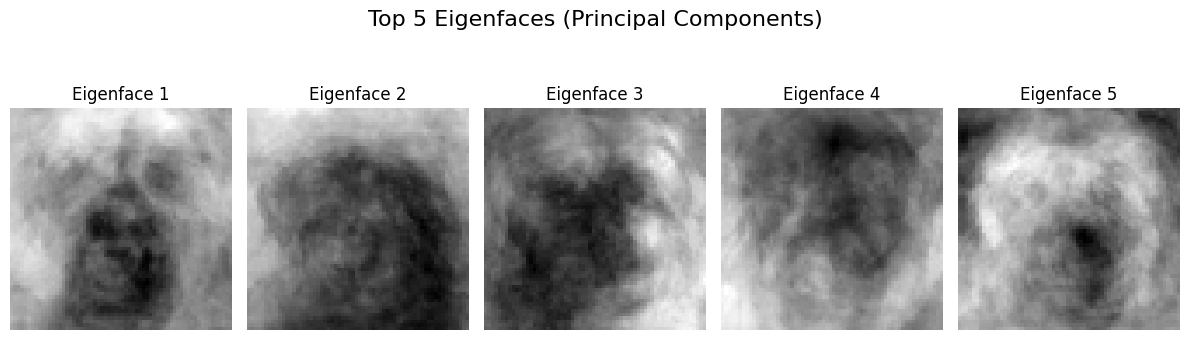

In [ ]:
# ============================
# 📌 Step 8.1: List and Interpret Top Eigenvalues & Eigenvectors
# ============================

import matplotlib.pyplot as plt

# ---- List Top 5 Eigenvalues ----
top_k = 5
print("Top 5 Eigenvalues (representing variance captured):\n")
for i in range(top_k):
    print(f"Eigenvalue {i+1}: {eigenvalues[i]}")

print("\nINTERPRETATION:")
print("""
• Each eigenvalue represents how much variance (information) is captured by its corresponding eigenvector.
• Larger eigenvalues = more important features captured from the dataset.
• These top eigenvectors define the main patterns that vary between images (e.g., shape, texture, brightness).
• The eigenvectors associated with the largest eigenvalues are called "principal components."
• When reshaped into 64×64 images, these eigenvectors are known as "Eigenfaces."
• They do NOT represent real images, but show the most dominant directions of variation among all 55 dog images.
""")


# ---- Visualize Top 5 Eigenvectors as Eigenfaces ----

plt.figure(figsize=(12, 4))
for i in range(top_k):
    eigenface = eigenvectors[:, i].reshape(64, 64)

    plt.subplot(1, top_k, i + 1)
    plt.imshow(eigenface, cmap='gray')
    plt.title(f"Eigenface {i+1}")
    plt.axis('off')

plt.suptitle("Top 5 Eigenfaces (Principal Components)", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# ============================
# 🧠 Step 9: Select Top N Principal Components
# ============================

# Let the user choose how many components (N) to keep
N = int(input("Enter number of principal components (e.g., 2, 5, or 10): "))

# Select the top N eigenvectors
principal_components = eigenvectors[:, :N]

print(f"✅ Selected top {N} principal components.")
print(f"Projection matrix shape: {principal_components.shape}")

Enter number of principal components (e.g., 2, 5, or 10): 2
✅ Selected top 2 principal components.
Projection matrix shape: (4096, 2)


In [ ]:
# ============================
# 🔄 Step 10: Transform (Project) Data onto Principal Components
# ============================

# Project the centered data onto the new N-dimensional space
projected_data = np.dot(centered_matrix, principal_components)

print(f"✅ Data projected into {N}-dimensional space.")
print(f"Projected data shape: {projected_data.shape}")  # Expected: (55, N)

✅ Data projected into 2-dimensional space.
Projected data shape: (55, 2)


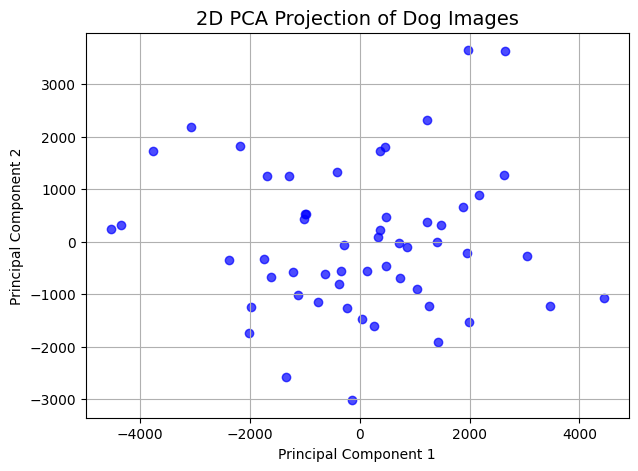

In [ ]:
# ============================
# 🎨 Step 11: Visualize 2D Projection (if N=2)
# ============================

import matplotlib.pyplot as plt

if N == 2:
    plt.figure(figsize=(7, 5))
    plt.scatter(projected_data[:, 0], projected_data[:, 1], color='blue', alpha=0.7)
    plt.title("2D PCA Projection of Dog Images", fontsize=14)
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.grid(True)
    plt.show()
else:
    print(f"📊 Visualization available only when N=2. Current N={N}.")

In [ ]:
# ============================
# 💾 Step 12: Save Projected Data
# ============================

# Save the projected data to a CSV file for further analysis
np.savetxt("projected_data.csv", projected_data, delimiter=",")
print("✅ Projected data saved as 'projected_data.csv'.")

✅ Projected data saved as 'projected_data.csv'.


In [ ]:
# ============================
# 🔁 Step 13: Decompression / Image Reconstruction
# ============================

# Reconstruct (approximate) the original data using the top N components
# Formula: X_reconstructed = (Z * P^T) + mean
# where:
#   Z = projected_data  (55 x N)
#   P = principal_components (4096 x N)
#   mean = mean_vector (4096,)

reconstructed_data = np.dot(projected_data, principal_components.T) + mean_vector

print("✅ Image reconstruction completed.")
print(f"Reconstructed data shape: {reconstructed_data.shape}")

✅ Image reconstruction completed.
Reconstructed data shape: (55, 4096)


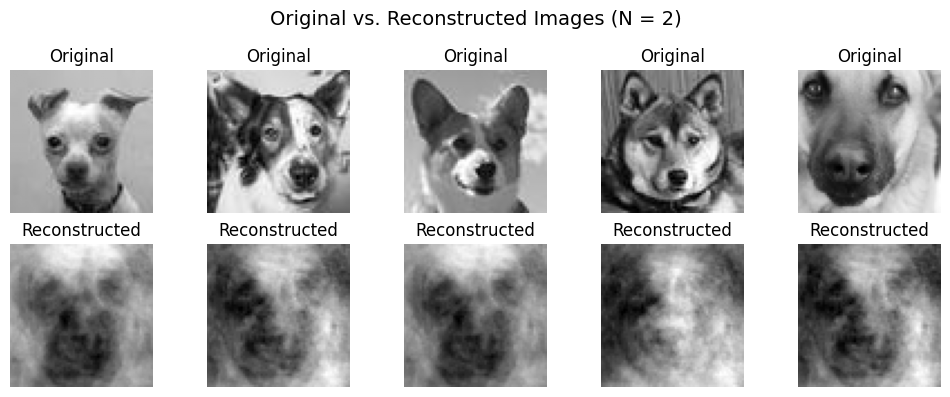

In [ ]:
# ============================
# 🧩 Step 14: Visualize Original vs. Reconstructed Images
# ============================

num_show = 5  # Number of samples to display for comparison

plt.figure(figsize=(10, 4))
for i in range(num_show):
    # Original
    plt.subplot(2, num_show, i + 1)
    plt.imshow(gray_images[i], cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed
    plt.subplot(2, num_show, i + 1 + num_show)
    reconstructed_img = reconstructed_data[i].reshape(64, 64)
    plt.imshow(reconstructed_img, cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.suptitle(f"Original vs. Reconstructed Images (N = {N})", fontsize=14)
plt.tight_layout()
plt.show()

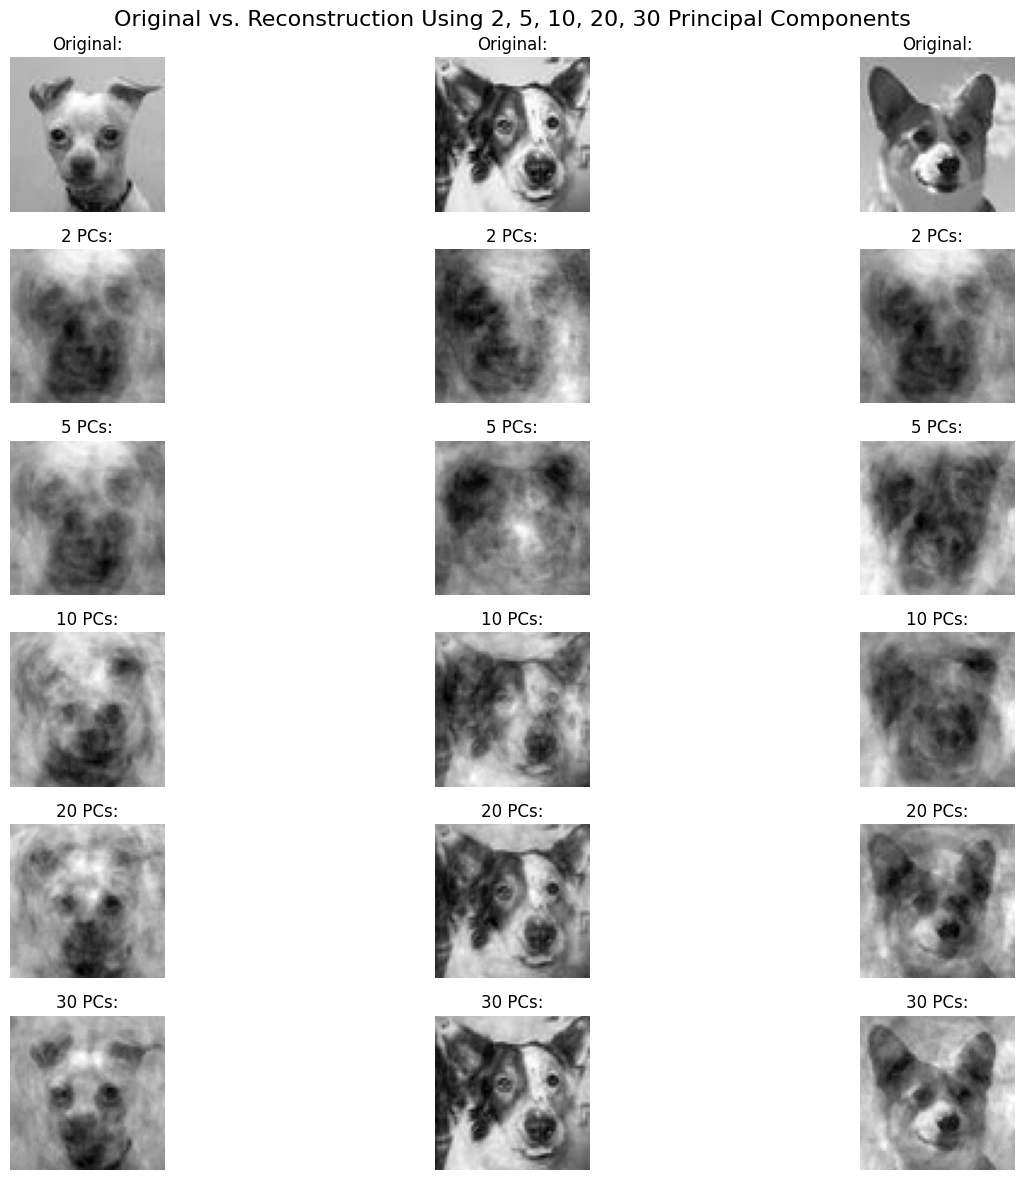

In [ ]:
# ============================
# 🏁 Requirement #7:
# Original + Reconstructed images using 2, 5, 10, 20, 30 components
# with component numbers beside each image
# ============================

components_list = [2, 5, 10, 20, 30]
num_show = 3  # Number of images to display

plt.figure(figsize=(15, 12))

# --------------------------------
# Row 1: Original uncompressed images
# --------------------------------
for i in range(num_show):
    plt.subplot(len(components_list) + 1, num_show, i + 1)
    plt.imshow(gray_images[i], cmap='gray')
    plt.title("Original:", fontsize=12)
    plt.axis('off')

# --------------------------------
# Following rows: Reconstructed images
# --------------------------------
for row, n_comp in enumerate(components_list):

    # Select top N eigenvectors
    P = eigenvectors[:, :n_comp]

    # Project to N-dimensional space
    Z = np.dot(centered_matrix, P)

    # Reconstruct
    reconstructed = np.dot(Z, P.T) + mean_vector

    # Show a few reconstructed images
    for i in range(num_show):
        plt.subplot(len(components_list) + 1, num_show, (row + 1) * num_show + i + 1)

        img = reconstructed[i].reshape(64, 64)
        plt.imshow(img, cmap='gray')
        plt.title(f"{n_comp} PCs:", fontsize=12)
        plt.axis('off')

plt.suptitle("Original vs. Reconstruction Using 2, 5, 10, 20, 30 Principal Components", fontsize=16)
plt.tight_layout()
plt.show()